# The RAG pipeline, stage by stage

Walks all five stages against the configured chapter, using the **same
`kidsrag` package** the CLI and UI use - nothing is reimplemented here, so
what this notebook demonstrates is what actually ships.

Run `python -m kidsrag ingest` once before running this.

In [1]:
import sys
sys.path.insert(0, "../src")

from kidsrag.config import load_config

cfg = load_config("../config.yaml")
print("chapter:  ", cfg.chapter_title)
print("pdf:      ", cfg.pdf_path.name)
print("artifacts:", cfg.chapter_dir)
print("gate:      max cosine >=", cfg.retrieval.gate_min_cosine)

chapter:   Data
pdf:       Help Your Kids with Computer Science_ A Unique Visual Step-by-Step Guide to Computers, Coding, and Communication ( PDFDrive ).pdf
artifacts: C:\Users\khalid\IdeaProjects\AI\Zidni-task\artifacts\data
gate:      max cosine >= 0.66


## Stage 1 - Extract

The chapter is located by **title** in the PDF's own table of contents. No
page numbers are hardcoded, which is what lets one config value retarget the
whole pipeline.

In [2]:
from kidsrag.ingest.pdf import open_document, resolve_chapter, spread_starts

doc = open_document(cfg.pdf_path)
chapter = resolve_chapter(doc, cfg.chapter_title)

print(f"{chapter.title}: pages {chapter.start_page}-{chapter.end_page} "
      f"({chapter.page_count} pages, {chapter.spread_count} spreads)")
print()
for title, page in spread_starts(doc, chapter):
    print(f"  p{page}  {title}")

Data: pages 80-97 (18 pages, 8 spreads)

  p82  Bits and digitization
  p84  Binary code
  p86  ASCII and unicode
  p88  Logic gates
  p90  Databases
  p92  Encoding images
  p94  Encoding audio and video
  p96  Encryption


## Stage 2 - Preprocess

The book uses a strict design system, so `(font, size)` identifies the role of
every piece of text. The table is **derived from this chapter**, never
hardcoded - that is what makes it work on other chapters.

Two things this got wrong on the first attempt, both caught by running it:

* a section heading shares its text block with the prose beneath it, so
  block-level classification never sees the heading -> classify by **line**
* diagram numerals are set at 18-19.5pt, between body and title, so
  "bigger than body = heading" turned `11000101` into a heading -> match the
  derived anchors **exactly**, and treat everything off-anchor as a label

In [3]:
from kidsrag.ingest.roles import derive_role_table

table = derive_role_table(doc, spread_starts(doc, chapter)[0][1], chapter.end_page)
print("derived anchors:", table.describe())

derived anchors: body=9.0 standfirst=10.5 heading=14.0 title=32.0


In [4]:
from kidsrag.ingest.text import build_passages

passages = build_passages(doc, chapter, table=table)
print(f"{len(passages)} passages, "
      f"mean {sum(len(p.text) for p in passages) // len(passages)} chars")
print()
for p in passages[:8]:
    print(f"  {len(p.text):5d}ch  {p.heading_display}")

44 passages, mean 701 chars

    140ch  Data › Bits and digitization
    436ch  Data › Bits and digitization › What is data?
    140ch  Data › Bits and digitization › 0 or 1
    608ch  Data › Bits and digitization › Why 0 and 1?
    215ch  Data › Bits and digitization › of music
   1132ch  Data › Bits and digitization › Data storage
    982ch  Data › Bits and digitization › Capacity
    175ch  Data › Binary code


In [5]:
# One passage in full. Diagram labels are kept OUT of the prose: fragments
# like '1x128 + 1x64' wreck a sentence embedding, but stay searchable by BM25.
p = next(x for x in passages if "Binary to decimal" in x.heading_display)

print(p.heading_display, "| pages", p.pages)
print()
print(p.text)
print()
print("--- labels (searchable, not part of the prose) ---")
print(p.labels[:300])

Data › Binary code › Binary to decimal | pages [84]

People usually count using the decimal system. This makes it difficult to look at a binary number and know what it represents. In a binary number, the least significant bit (LSB) is the bit furthest to the right and the most significant bit (MSB) is the bit furthest to the left. Between these two, the range of values that can be written doubles with each digit added. Conversion The first column in the binary system is the LSB on the right and is equivalent to one. Subsequently, each column is worth double the column to its right. To get the equivalent decimal value of a binary number, multiply the value of each column with its respective binary digit and then add all the individual results. 1x128 + 1x64 + 0x32 + 0x16 + 0x8 + 1x4 + SEE ALSO ‹ 38–39 The computer chip ‹ 40–41 How modern computers compute ‹ 80–81 Bits and digitization 90–91 › Encoding images 92–93 › Encoding audio and video = 1111111111111111111 ABC = 01000001 01000010 0

### Page images

Every page in this PDF is a single full-page bitmap with no separately
addressable figures, so **whole pages** are the visual unit. A figure-cropping
prototype exists but over-segments - see `docs/technical-decisions.md` section 2.

page image for this passage: ['pages/p084.png']


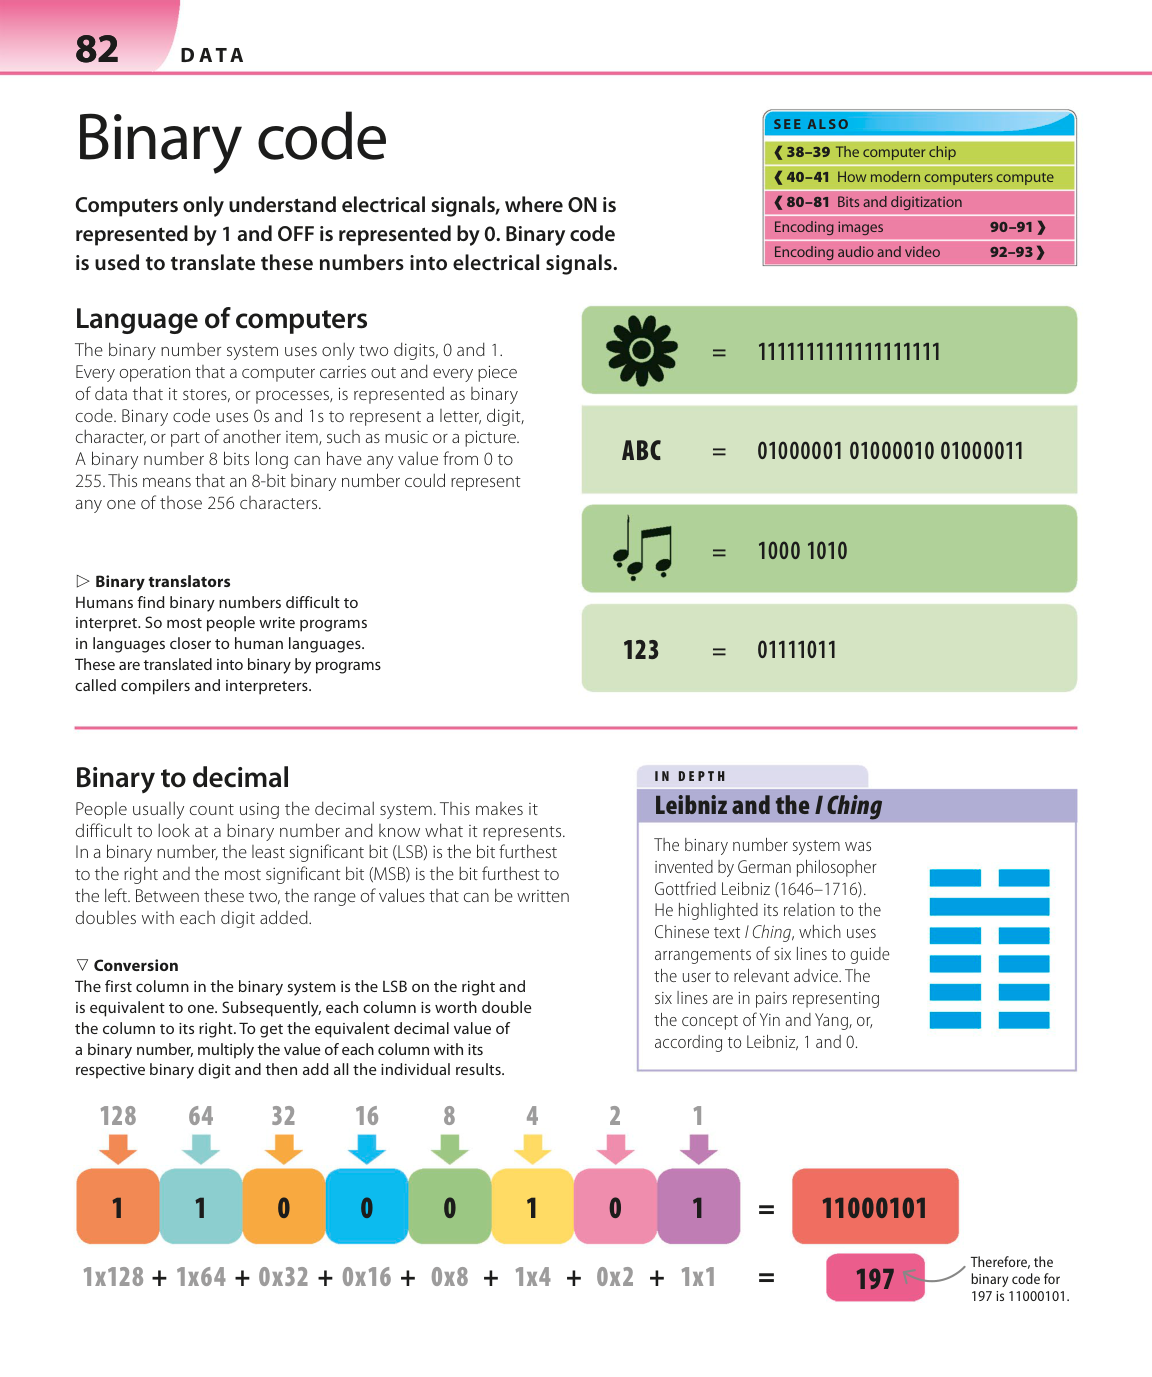

In [6]:
from IPython.display import Image, display
from kidsrag.index import store

# The cells above chunked live, without an image map, so page_images is empty
# there. The persisted passages written by `ingest` carry their page images.
stored = store.load_passages(cfg)
sp = next(x for x in stored if "Binary to decimal" in x.heading_display)

print("page image for this passage:", sp.page_images)
display(Image(filename=str(cfg.chapter_dir / sp.page_images[0]), width=430))

## Stage 3 - Index

Embeddings run locally via `fastembed` (ONNX, no PyTorch). Vectors come back
L2-normalised, so cosine similarity is a plain dot product.

No vector database: at ~44 passages, brute force is exact and sub-millisecond.

In [7]:
from kidsrag.index import store

vectors = store.load_embeddings(cfg)
manifest = store.load_manifest(cfg)

print("vectors:   ", vectors.shape, vectors.dtype)
print("normalised:", abs(float((vectors[0] ** 2).sum()) - 1.0) < 1e-4)
print("model:     ", manifest.embedding_model)
print("cache key: ", manifest.cache_key[:16], "...")

vectors:    (44, 384) float32
normalised: True
model:      BAAI/bge-small-en-v1.5
cache key:  04a05fb2ed7cd34b ...


## Stage 4 - Retrieve

Dense cosine **and** BM25, fused with Reciprocal Rank Fusion. Children ask in
plain words (semantics win); the chapter is full of exact tokens like `ASCII`
and `11000101` (lexical wins).

**The refusal gate uses raw cosine, not the fused score.** RRF scores depend
only on rank, so the top fused score is near-constant whether a question is
relevant or not - measured 0.0315 for a real question against 0.0296 for
"What did I eat for breakfast?". Cosine separates cleanly.

In [8]:
from kidsrag.index.retrieve import Retriever

retriever = Retriever.load(cfg)

for q in ["What is binary code?", "How are pictures stored?", "What is a gaming console?"]:
    r = retriever.retrieve(q)
    gate = "ANSWER" if r.passed_gate else "REFUSE"
    print(f"{gate}  cos={r.max_cosine:.4f}  fused={r.top_score:.5f}   {q}")
    for passage, score in list(zip(r.passages, r.scores))[:3]:
        print(f"          {score:.5f}  {passage.heading_display}")
    print()

C:\Users\khalid\IdeaProjects\AI\Zidni-task\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


ANSWER  cos=0.7978  fused=0.03178   What is binary code?
          0.03178  Data › ASCII and unicode
          0.03151  Data › Binary code
          0.03080  Data › Binary code › Binary to decimal

ANSWER  cos=0.7196  fused=0.03252   How are pictures stored?
          0.03252  Data › Encoding images › Why are image files so large?
          0.03055  Data › Databases › Using databases
          0.03037  Data › Bits and digitization › Capacity

REFUSE  cos=0.5204  fused=0.03202   What is a gaming console?
          0.03202  Data › Bits and digitization › What is data?
          0.03175  Data › Databases › What are databases?
          0.03031  Data › Bits and digitization



## Stage 5 - Generate

Grounding is enforced **twice**:

1. a pre-generation gate that refuses below threshold *without a network call*
2. a deterministic citation check that discards any answer citing nothing -
   plain string matching, so it holds whether or not the model complied

All three outcomes (`Answer`, `Refusal`, `Trouble`) pass through `render.py`,
the only module that produces child-facing text.

In [9]:
from kidsrag.generate.answer import answer_question
from kidsrag.render import render

question = "What is binary code?"
result = retriever.retrieve(question)
view = render(answer_question(cfg, question, result))

print(f"[{view.kind}]")
print()
print(view.text)
if view.images:
    display(Image(filename=str(cfg.chapter_dir / view.images[0]), width=430))

[trouble]

Something went wrong on my side, sorry about that!

It's not a problem with your question. Please try asking again in a moment.


Without an API key the cell above returns **Trouble** ("something went wrong"),
not a refusal - a broken service must never be presented as "the book doesn't
say". The cell below needs no key at all: the gate refuses before the model is
ever called.

In [10]:
q = "What is a gaming console?"   # chapter 3 of this book, not this chapter
view = render(answer_question(cfg, q, retriever.retrieve(q)))
print(f"[{view.kind}]")
print(view.text)

[refusal]
I couldn't find anything about that in this part of the book.

This part is all about **data** — things like binary code, secret codes, how pictures and sounds are stored, and how computers keep information in databases.

Would you like to ask me about one of those?


## The evaluation set

Must-refuse questions come mostly from **other chapters of the same book**.
That tests chapter scoping, which is the thing that can actually break;
nonsense questions prove very little.

`retrieval_only=True` exercises the gate without spending API calls.

In [11]:
from pathlib import Path
from kidsrag.evaluate import run_eval

run_eval(cfg, Path("../tests/eval/questions.yaml"), retrieval_only=True)

Evaluation (retrieval gate only) - 18 questions

      cos  expected   actual     question
ok 0.7978  answerable answerable What is binary code?
ok 0.6811  answerable answerable How does a computer store a letter?
ok 0.7880  answerable answerable What is ASCII?
ok 0.7185  answerable answerable How are pictures stored on a computer?
ok 0.8678  answerable answerable What is encryption?
ok 0.8814  answerable answerable What is a database?
ok 0.8112  answerable answerable What does a logic gate do?
ok 0.8102  answerable answerable Why do computers use 0 and 1?
ok 0.7062  answerable answerable How is sound stored on a computer?
ok 0.7116  answerable answerable What is a pixel?
ok 0.5204  refuse     refuse     What is a gaming console?
ok 0.5971  refuse     refuse     What is a compiler?
ok 0.6508  refuse     refuse     What is a search engine?
ok 0.6030  refuse     refuse     What is decomposition in computational thinking?
ok 0.5714  refuse     refuse     What is a wearable computer?
ok 0.

0

## Switching chapters

Change `chapter.title` in `config.yaml` and re-run `ingest`. Nothing else.
Page ranges come from the TOC and each chapter gets its own artifacts
directory, so chapters coexist.

```yaml
chapter:
  title: "Programming techniques"
```

In [12]:
other = resolve_chapter(doc, "Programming techniques")
print(f"{other.title}: pages {other.start_page}-{other.end_page}, "
      f"{other.spread_count} spreads")

other_table = derive_role_table(doc, spread_starts(doc, other)[0][1], other.end_page)
print("anchors on a chapter it was never tuned on:", other_table.describe())
print("identical to the Data chapter:", other_table.describe() == table.describe())

Programming techniques: pages 98-117, 9 spreads

anchors on a chapter it was never tuned on: body=9.0 standfirst=10.5 heading=14.0 title=32.0
identical to the Data chapter: True
